# 01 · Exploratory data analysis

What does the credit-card dataset look like, and what does it need before clustering?

**Questions**
1. Is the data complete and clean?
2. How are the features distributed?
3. Which features move together?
4. What preprocessing follows from the answers?

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from segmentation.data import load_data, clean_data
from segmentation.preprocess import engineer_features, SkewLogTransformer

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)

In [2]:
raw = load_data()
print(raw.shape)
raw.head()

(8950, 18)


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


## 1. Data quality

In [3]:
missing = raw.isna().sum()
missing[missing > 0]

CREDIT_LIMIT          1
MINIMUM_PAYMENTS    313
dtype: int64

Only two columns have gaps: `CREDIT_LIMIT` (1 row) and `MINIMUM_PAYMENTS` (313 rows). A missing minimum payment means no minimum was ever due, so it is filled with **0** rather than a median. The single customer with no credit limit is dropped.

In [4]:
df, ids = clean_data(raw)
print(df.shape, 'missing:', int(df.isna().sum().sum()), 'duplicates:', int(df.duplicated().sum()))

(8949, 17) missing: 0 duplicates: 0


## 2. Distributions

Most amount columns are strongly right-skewed: a few whales, many near-zero customers.

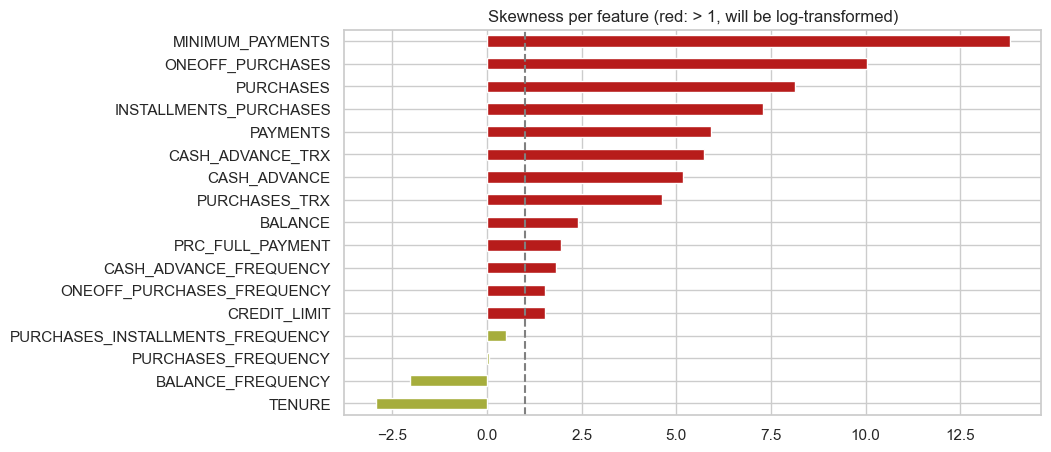

In [5]:
skew = df.skew().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 5))
skew.plot.barh(ax=ax, color=np.where(skew > 1, '#B71C1B', '#A6AD3C'))
ax.axvline(1, ls='--', color='grey'); ax.invert_yaxis()
ax.set_title('Skewness per feature (red: > 1, will be log-transformed)')
plt.show()

Log-transformed: ['BALANCE', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'ONEOFF_PURCHASES_FREQUENCY', 'CASH_ADVANCE_FREQUENCY', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT']


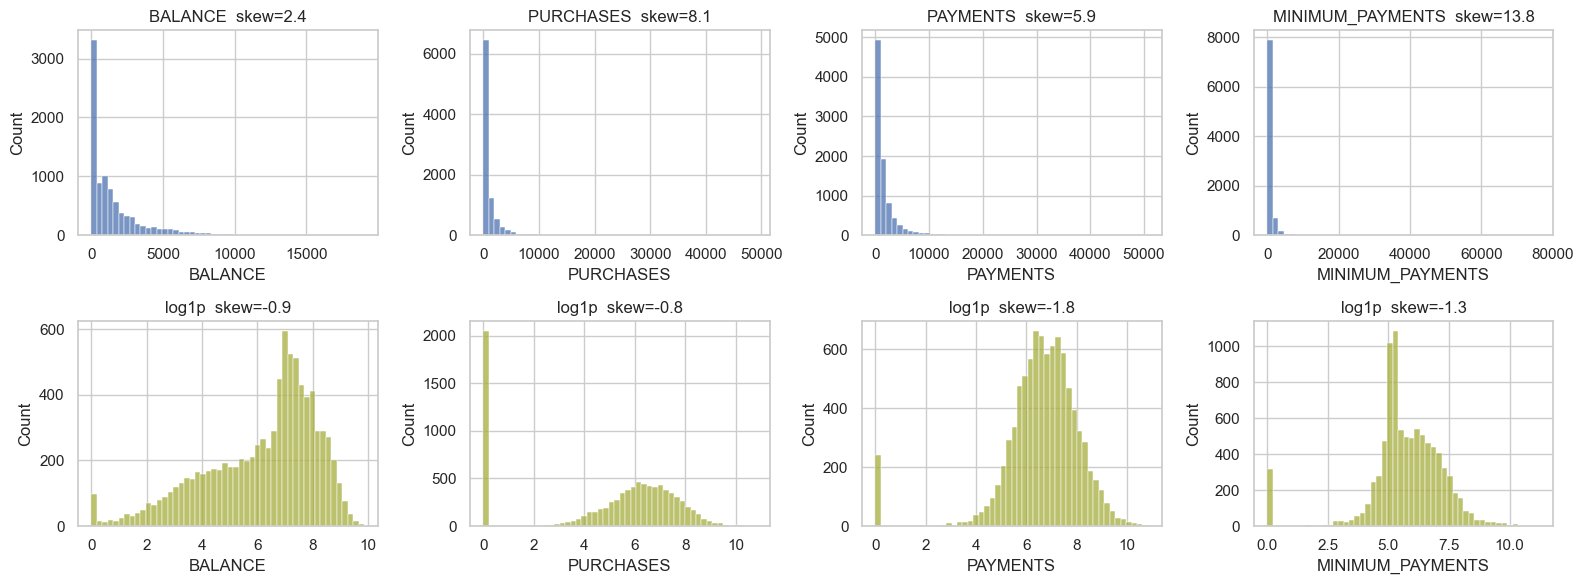

In [6]:
t = SkewLogTransformer().fit(df)
print('Log-transformed:', t.log_columns_)
logged = t.transform(df)
cols = ['BALANCE', 'PURCHASES', 'PAYMENTS', 'MINIMUM_PAYMENTS']
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for j, c in enumerate(cols):
    sns.histplot(df[c], bins=50, ax=axes[0, j]); axes[0, j].set_title(f'{c}  skew={df[c].skew():.1f}')
    sns.histplot(logged[c], bins=50, ax=axes[1, j], color='#A6AD3C'); axes[1, j].set_title(f'log1p  skew={logged[c].skew():.1f}')
plt.tight_layout(); plt.show()

A `log1p` transform tames the skew without discarding extreme customers (they are often the most interesting ones, so clipping outliers would throw away signal).

## 3. Relationships

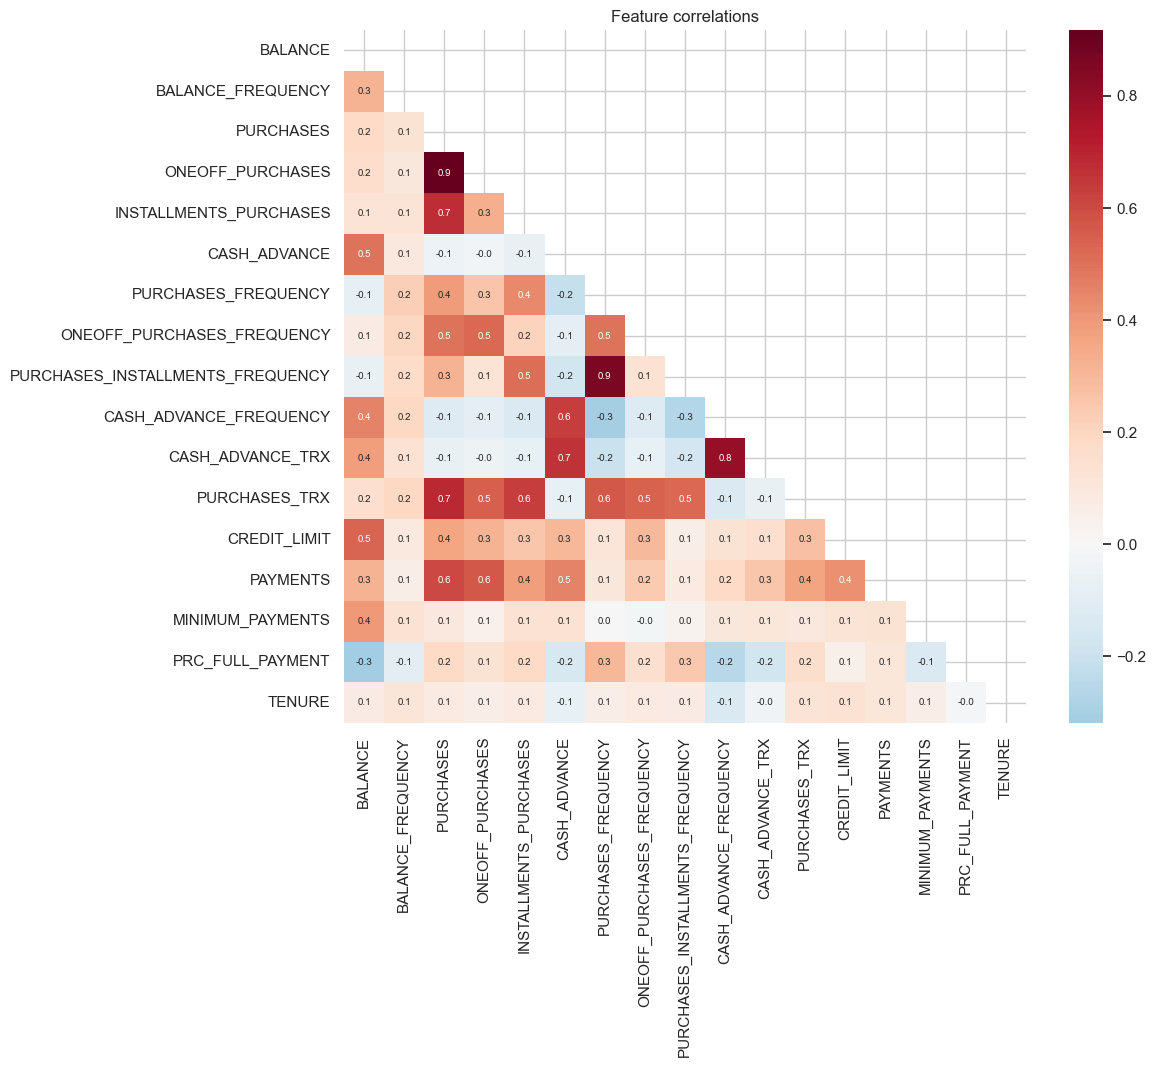

In [7]:
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(11, 9))
sns.heatmap(corr, mask=mask, cmap='RdBu_r', center=0, annot=True, fmt='.1f', annot_kws={'size': 7})
plt.title('Feature correlations')
plt.show()

In [8]:
pairs = corr.where(~mask).stack().abs().sort_values(ascending=False).head(8)
pairs.round(2).to_frame('|r|')

,,|r|
ONEOFF_PURCHASES,PURCHASES,0.92
PURCHASES_INSTALLMENTS_FREQUENCY,PURCHASES_FREQUENCY,0.86
CASH_ADVANCE_TRX,CASH_ADVANCE_FREQUENCY,0.80
PURCHASES_TRX,PURCHASES,0.69
INSTALLMENTS_PURCHASES,PURCHASES,0.68
CASH_ADVANCE_TRX,CASH_ADVANCE,0.66
CASH_ADVANCE_FREQUENCY,CASH_ADVANCE,0.63
PURCHASES_TRX,INSTALLMENTS_PURCHASES,0.63


Purchases, one-off purchases and instalment purchases overlap heavily, as do cash-advance amount, frequency and transaction count. That redundancy is a reason to look at **ratios** rather than only raw amounts.

## 4. Engineered features

In [9]:
feats = engineer_features(df)
new = ['UTILIZATION', 'PAYMENT_RATIO', 'AVG_PURCHASE', 'CASH_ADVANCE_SHARE']
feats[new].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
UTILIZATION,8949.0,0.39,0.35,0.0,0.04,0.3,0.72,1.50
PAYMENT_RATIO,8949.0,6.14,10.88,0.0,0.33,1.4,7.53,50.00
AVG_PURCHASE,8949.0,73.88,160.53,0.0,11.99,41.4,78.67,5981.67
CASH_ADVANCE_SHARE,8949.0,0.38,0.44,0.0,0.00,0.0,0.95,1.00


- `UTILIZATION`: balance / credit limit, a risk signal
- `PAYMENT_RATIO`: payments / balance, how fast customers repay
- `AVG_PURCHASE`: ticket size
- `CASH_ADVANCE_SHARE`: how much of card use is cash

**Next:** `02_segmentation.ipynb` clusters the log-scaled features.